# Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import datetime

import warnings
warnings.filterwarnings("ignore")

In [3]:
start_date, end_date = "2020-01-01", "2025-01-01"
stock = "AAPL"

In [ ]:
df = yf.download("AAPL", start="2020-01-01", end="2025-01-01")


In [6]:
df['Close']['AAPL']

Date
2020-01-02     72.538513
2020-01-03     71.833298
2020-01-06     72.405678
2020-01-07     72.065147
2020-01-08     73.224426
                 ...    
2024-12-24    257.286682
2024-12-26    258.103729
2024-12-27    254.685867
2024-12-30    251.307877
2024-12-31    249.534180
Name: AAPL, Length: 1258, dtype: float64

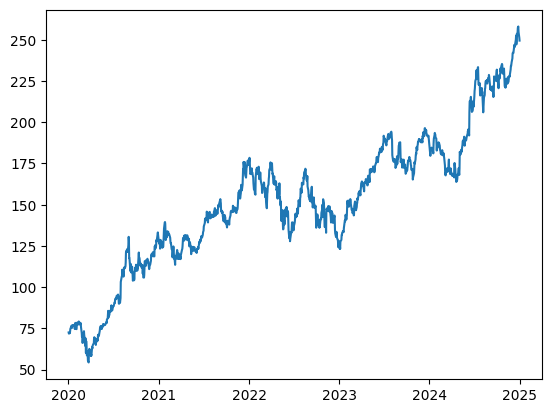

In [7]:

plt.plot(df['Close']['AAPL'])
plt.show()

In [8]:
stock_data = pd.DataFrame(df['Close']['AAPL'])
stock_data.columns = ['Price']

stock_data.head()

,Price
Date,
2020-01-02,72.538513
2020-01-03,71.833298
2020-01-06,72.405678
2020-01-07,72.065147
2020-01-08,73.224426


# Simple Moving Average (SMA)

In [9]:
short_period, long_period = 50, 200
short_sma = stock_data['Price'].rolling(window=short_period).mean()
long_sma = stock_data['Price'].rolling(window=long_period).mean()

In [10]:
short_sma

Date
2020-01-02           NaN
2020-01-03           NaN
2020-01-06           NaN
2020-01-07           NaN
2020-01-08           NaN
                 ...    
2024-12-24    234.988823
2024-12-26    235.495564
2024-12-27    235.975156
2024-12-30    236.379822
2024-12-31    236.692278
Name: Price, Length: 1258, dtype: float64

In [11]:
stock_data['short_sma'] = short_sma
stock_data['long_sma'] = long_sma

In [12]:
stock_data.head()

,Price,short_sma,long_sma
Date,,,
2020-01-02,72.538513,NaN,NaN
2020-01-03,71.833298,NaN,NaN
2020-01-06,72.405678,NaN,NaN
2020-01-07,72.065147,NaN,NaN
2020-01-08,73.224426,NaN,NaN


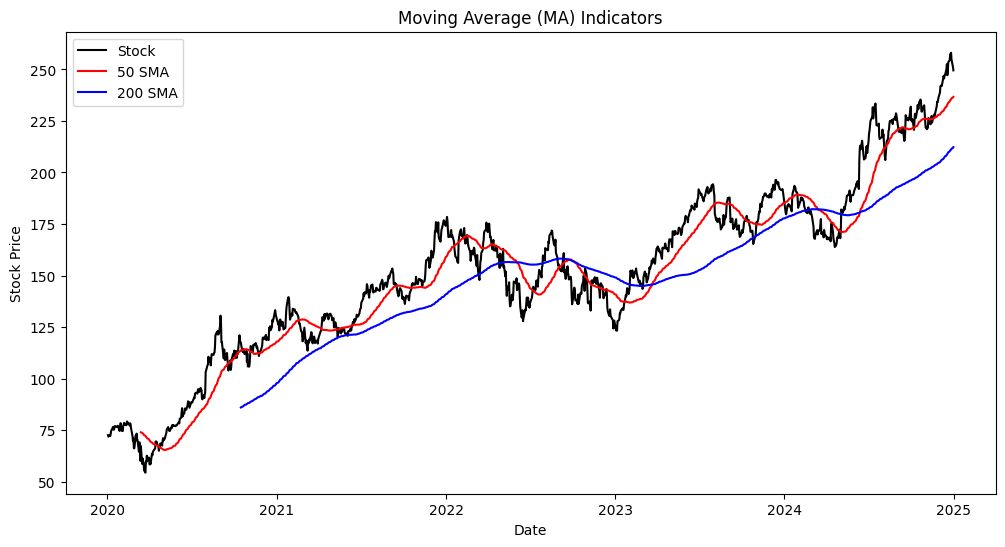

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Price'], label="Stock Price", color="black")
plt.plot(stock_data["short_sma"], label=f"{short_period} SMA", color="red")
plt.plot(stock_data["long_sma"], label=f"{long_period} SMA", color="blue")
plt.title("Moving Average (MA) Indicators")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend(['Stock', f'{short_period} SMA', f"{long_period} SMA"])
plt.show()

# Exponential Moving Average (EMA)

In [14]:
short_period, long_period = 50, 200
short_ema = stock_data['Price'].ewm(span=short_period, adjust=False).mean()
long_ema = stock_data['Price'].ewm(span=long_period, adjust=False).mean()

In [15]:
stock_data['short_ema'] = short_ema
stock_data['long_ema'] = long_ema

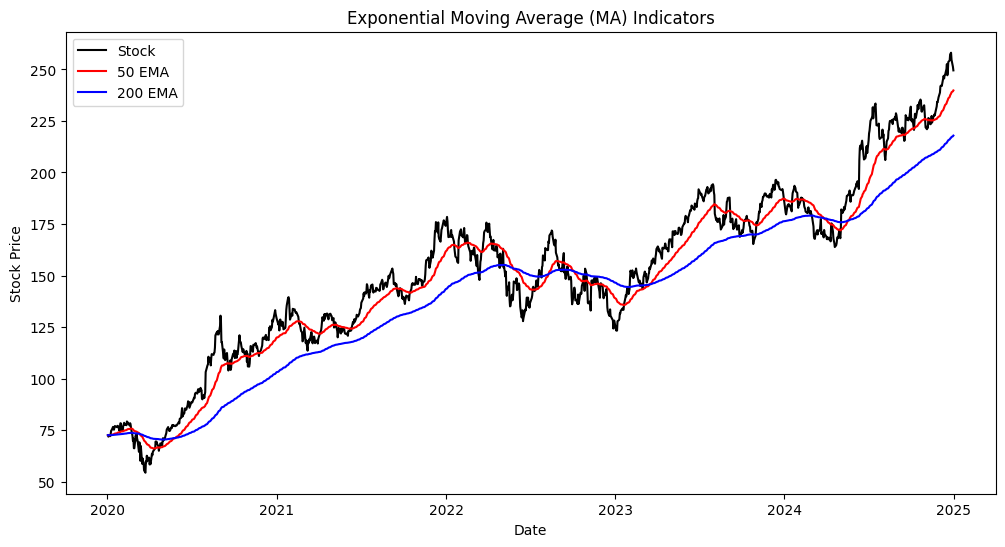

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Price'], label="Stock Price", color="black")
plt.plot(stock_data["short_ema"], label=f"{short_period} EMA", color="red")
plt.plot(stock_data["long_ema"], label=f"{long_period} EMA", color="blue")
plt.title("Exponential Moving Average (MA) Indicators")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend(['Stock', f'{short_period} EMA', f"{long_period} EMA"])
plt.show()

# Both SMA and EMA

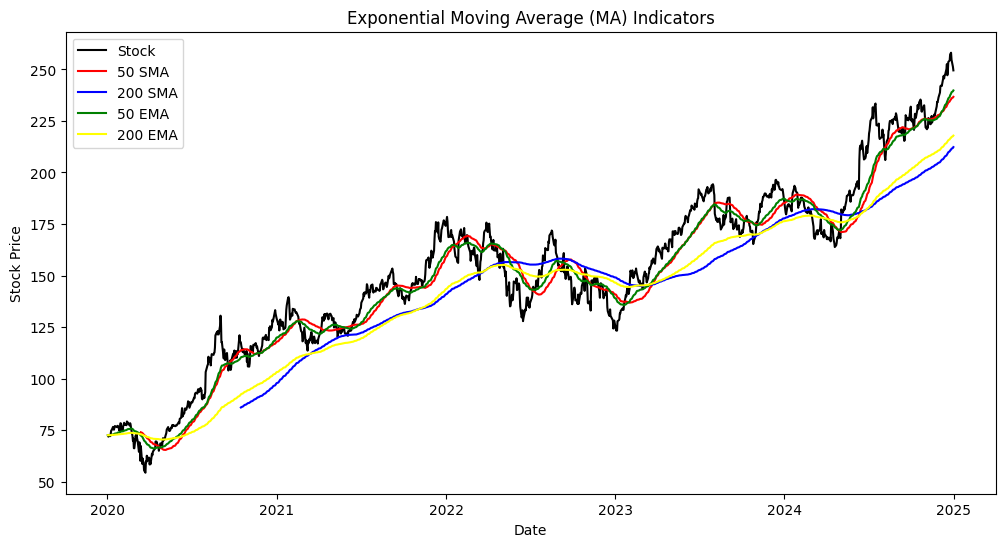

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Price'], label="Stock Price", color="black")
plt.plot(stock_data["short_sma"], label=f"{short_period} SMA", color="red")
plt.plot(stock_data["long_sma"], label=f"{long_period} SMA", color="blue")
plt.plot(stock_data["short_ema"], label=f"{short_period} EMA", color="green")
plt.plot(stock_data["long_ema"], label=f"{long_period} EMA", color="yellow")
plt.title("Exponential Moving Average (MA) Indicators")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend(['Stock', f'{short_period} SMA', f"{long_period} SMA", f'{short_period} EMA', f"{long_period} EMA"])
plt.show()

# Moving Average Crossover

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import datetime

import warnings
warnings.filterwarnings("ignore")

[*********************100%***********************]  1 of 1 completed


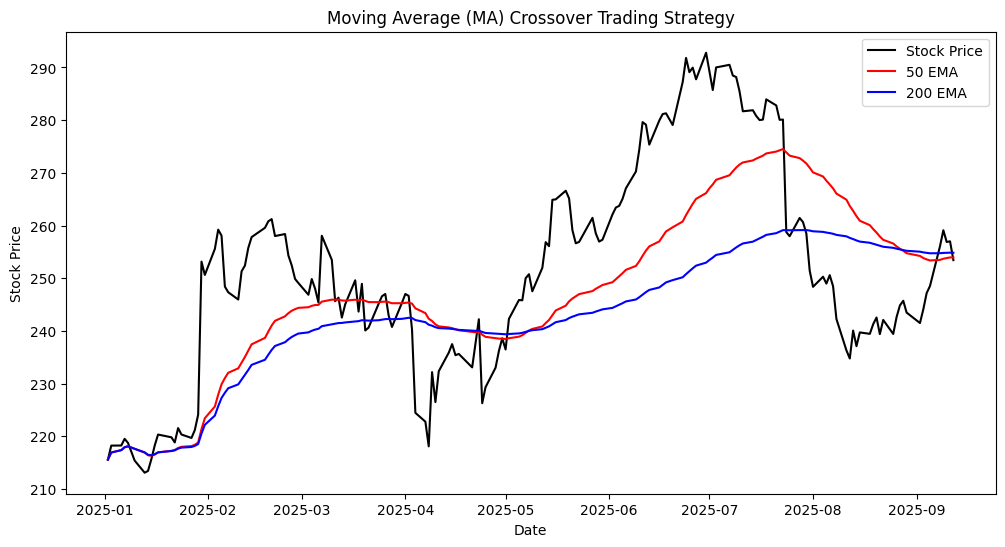

Profit of the trading strategy: -2.01%


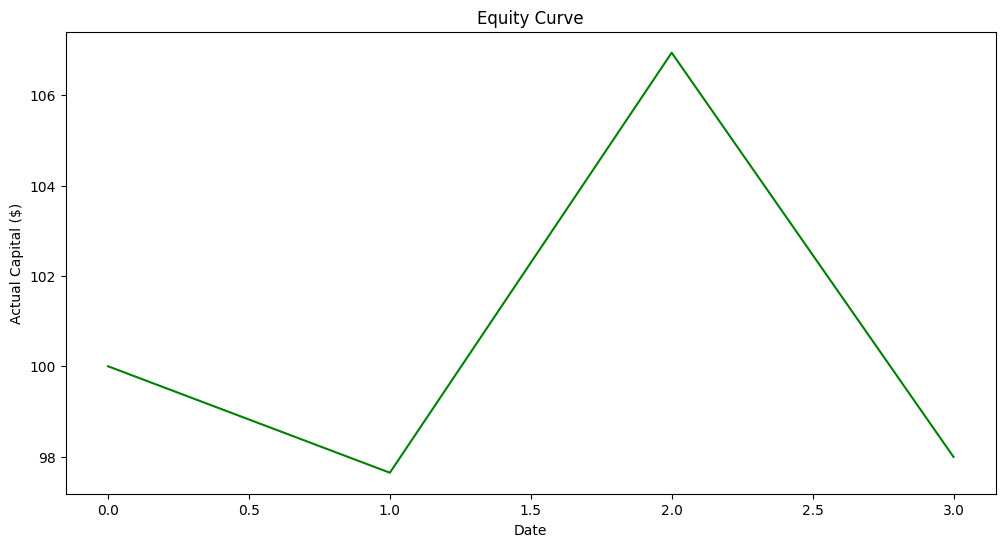

[100, 97.64203493906172, 106.94471019986261, 97.99231549315795]


In [ ]:
class MovingAverageCrossover:

    def __init__(self, capital, stock, start, end, short_period, long_period):
        self.data = None
        self.is_long = False
        self.short_period = short_period
        self.long_period = long_period
        self.capital = capital
        self.equity = [capital]
        self.stock = stock
        self.start = start
        self.end = end

    def download_data(self):
        ticker = yf.download(self.stock, self.start, self.end)
        stock_data = pd.DataFrame(ticker['Close'][self.stock])
        stock_data.columns = ['Price']
        self.data = stock_data

    def construct_signals(self):
        self.data['short_ema'] = self.data['Price'].ewm(span=self.short_period).mean()
        self.data['long_ema'] = self.data['Price'].ewm(span=self.long_period).mean()

    def simulate(self):
        # We consider all the trading days and decide whether to open a long position or not
        price_when_to_buy = 0
        for index, row in self.data.iterrows():
            # Closing the Long Position
            if row.short_ema < row.long_ema and price_when_to_buy > 0 and self.is_long: 
                self.equity.append((self.capital * row.Price / price_when_to_buy).item())
                self.is_long = False
                # print("SELL")
            elif row.short_ema > row.long_ema and not self.is_long:
                # Open a Long position
                price_when_to_buy = row['Price']
                self.is_long = True
                # print("BUY")
    
    def plot_equity(self):
        print(
            "Profit of the trading strategy: %.2f%%" 
            %((float(self.equity[-1]) - float(self.equity[0])) / float(self.equity[0]) * 100)
        )
        plt.figure(figsize=(12, 6))
        plt.title("Equity Curve")
        plt.plot(self.equity, label="Stock Price", color="green")
        plt.xlabel("Date")
        plt.ylabel("Actual Capital ($)")
        plt.show()

    def plot_signals(self):
        plt.figure(figsize=(12, 6))
        plt.plot(self.data['Price'], label="Stock Price", color="black")
        plt.plot(self.data['short_ema'], label=f"{self.short_period} EMA", color="red")
        plt.plot(self.data['long_ema'], label=f"{self.long_period} EMA", color="blue")
        plt.title("Moving Average (MA) Crossover Trading Strategy")
        plt.xlabel("Date")
        plt.ylabel("Stock Price")
        plt.legend(['Stock Price', f"{self.short_period} EMA", f"{self.long_period} EMA"])
        plt.show()


if __name__ == "__main__":
    start_date = datetime.datetime(2025, 1, 1)
    end_date = datetime.datetime(2025, 9, 14)

    strategy = MovingAverageCrossover(100, "IBM", start_date, end_date, 50, 200)
    strategy.download_data()
    strategy.construct_signals()
    strategy.plot_signals()
    strategy.simulate()
    strategy.plot_equity()
    print(strategy.equity)

In [59]:
from yahooquery import search

result = search("Reliance")
result['quotes'][0]['symbol']


'RELI'

In [ ]:
from datetime import datetime, date, time
    

TypeError: 'getset_descriptor' object is not callable

In [9]:
import plotly.graph_objects as go

ModuleNotFoundError: No module named 'plotly'